# Day 15 — CloudTrail Event Visualization

In [1]:
import sys
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()

if not (project_root / "src").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.load_cloudtrail import load_cloudtrail
from src.cloudtrail_adapter import adapt_cloudtrail_event

In [ ]:
file_path = project_root / "data" / "synthetic_cloudtrail.json"

raw_events = load_cloudtrail(file_path)

normalized_events = [
    adapt_cloudtrail_event(record)
    for record in raw_events
]

df = pd.DataFrame(normalized_events)

Invalid source IP address.
Invalid source IP address.
Invalid source IP address.
Invalid source IP address.
Invalid source IP address.
Invalid source IP address.
Invalid source IP address.
Invalid source IP address.
Invalid source IP address.
Invalid source IP address.


In [5]:


# Convert timestamps to UTC datetime
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

# Using JSON seralization to create json strings of the record that can be checked for duplicates
df["raw_record_json"] = df["raw_record"].apply(
    lambda record: json.dumps(record, sort_keys=True)
)

#Remove duplicate rows
df_clean = df.drop_duplicates(
    subset=["raw_record_json"]
).copy()

#Creaet event date using timestamp 
df_clean["event_date"] = df_clean["timestamp"].dt.date



In [6]:
print("Cleaned records:", len(df_clean))
print("Unique dates:", df_clean["event_date"].nunique())

Cleaned records: 95
Unique dates: 5


In [7]:
daily_volume = (
    df_clean.groupby("event_date")
    .size()
    .reset_index(name="event_count")
)

daily_volume

,event_date,event_count
0,2026-11-10,17
1,2026-11-11,19
2,2026-11-12,17
3,2026-11-13,17
4,2026-11-14,25


In [9]:
assert daily_volume["event_count"].sum() == len(df_clean)

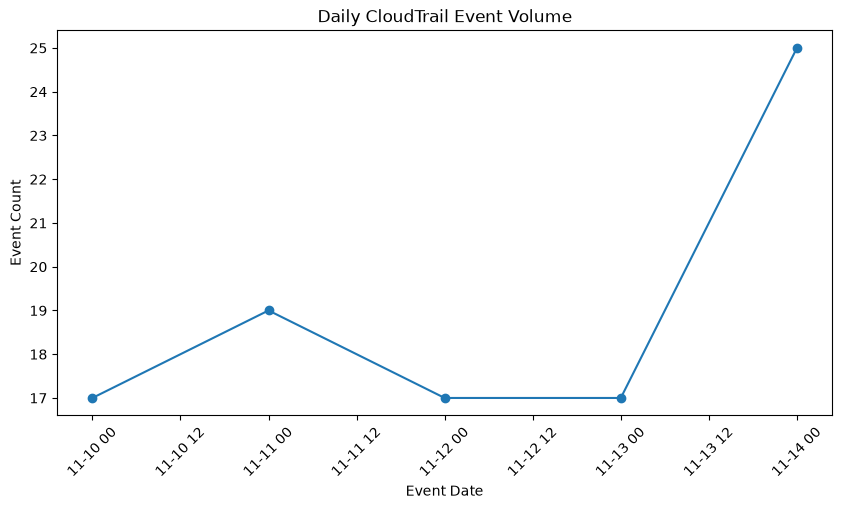

In [14]:
plt.figure(figsize= (10,5))
plt.title("Daily CloudTrail Event Volume")
plt.xlabel("Event Date")
plt.ylabel("Event Count")
plt.xticks(rotation=45)
plt.plot(
    daily_volume["event_date"],
    daily_volume["event_count"],
    marker="o"
)

plt.show()

In [ ]:
sorted_by_eventcount = (
    daily_volume.sort_values(by="event_count", ascending=False))

sorted_by_eventcount.head(1)

,event_date,event_count
4,2026-11-14,25
1,2026-11-11,19
0,2026-11-10,17
2,2026-11-12,17
3,2026-11-13,17


In [18]:
action_counts = (
    df_clean.groupby("action")
    .size()
    .reset_index(name="action_count")
)
action_counts.head()



,action,action_count
0,ConsoleLogin,32
1,GetObject,30
2,PutObject,33


In [23]:
assert action_counts["action_count"].sum() == len(df_clean)

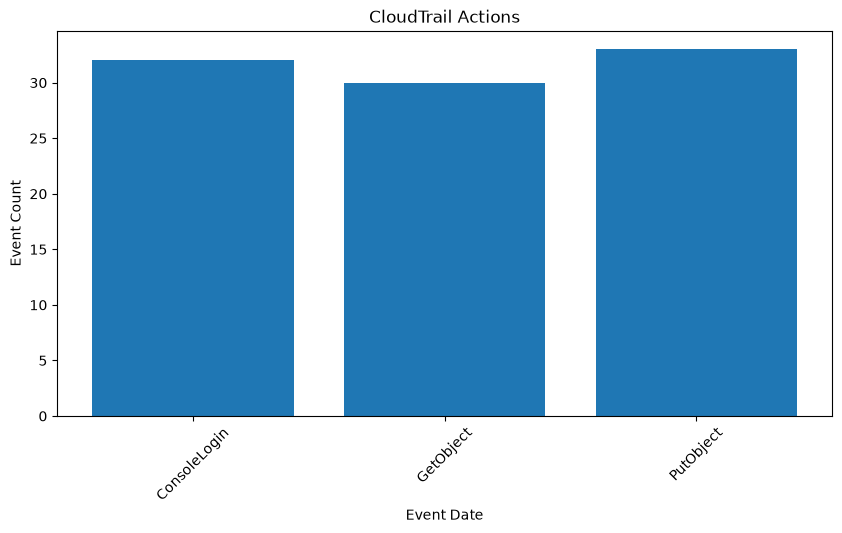

In [ ]:
plt.figure(figsize= (10,5))
plt.title("CloudTrail Actions")
plt.xlabel("Action")
plt.ylabel("Action Count")
plt.xticks(rotation=45)
plt.bar(
    action_counts["action"],
    action_counts["action_count"]
)

plt.show()

### Day 15 — CloudTrail Event Visualization

Visualized daily CloudTrail event volume and action distribution using Matplotlib. November 14 had the highest observed activity, with 25 events, while `PutObject` was the most frequently recorded action.

These findings show differences in activity but do not establish malicious behavior, particularly because the dataset is synthetic.

Further investigation would examine user identities, source IP addresses, accessed resources, permissions, and historical behavior to determine whether the activity warrants security investigation.